## **Summary**

#### 1. Data selection

#### 2. Mining communities with Leiden (basic mobility graph) - visualization and multiple resolution values runs

#### 3. Mining communities with Leiden (spatial + mobility graph) - visualization and multiple resolution values runs

#### 4. Mining communities with Leiden (probability graph) - visualization and multiple resolution values runs

#### 5. Running definitive method with consensus (**go here**)

#### 6. Comparing induced vehicles clusters' from the discovered communities

#### 7. Conclusions

In [1]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils, graph_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

## **1. Get data**

In [2]:
trace = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("trace summary:\n" + deploy_utils.Trace.summarize_trace(trace=trace))

trace summary:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


## **2. Mining communities (basic mobility graph)**

In [3]:
basic_cell_graph = graph_utils.Graph.create_cell_transition_graph(trace=trace)

In [4]:
print(f"Nodes: {basic_cell_graph.number_of_nodes()}")
print(f"Edges: {basic_cell_graph.number_of_edges()}")

Nodes: 4225
Edges: 15576


Modularity: 0.9675766708752673
N. communities: 3


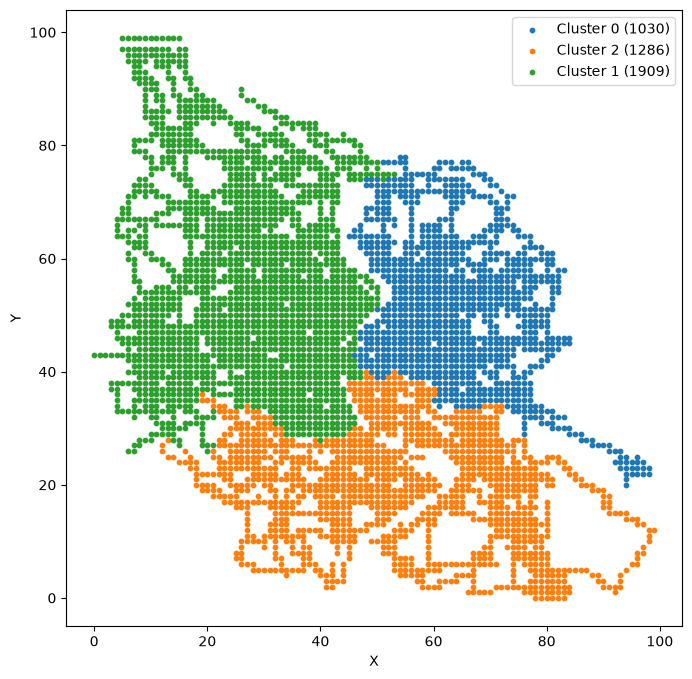

In [ ]:
import random
import time
random.seed(time.time())
communities_res = graph_utils.Graph.detect_leiden_communities(
    objective_function="modularity", graph=basic_cell_graph, resolution=0.045)

cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)
cell_df = graph_utils.Graph.assign_graph_communities_to_celldf(
    celldf=cell_df, communities=communities_res[0])

print(f"Modularity: {communities_res[1]}")
print(f"N. communities: {communities_res[2]}")

plot_utils.Plot.plot_cell_clusters(
    clusters_dict=cluster_utils.Clustering.clustered_celldf_to_dict(df=cell_df),
    marker_size=10)
plt.show()

In [ ]:
basic_cell_graph_res = graph_utils.Graph.evaluate_leiden(
    graph=basic_cell_graph,
    resolutions=np.linspace(start=0.1, stop=0.001, num=300), n_runs=50)

In [ ]:
basic_cell_graph_res.head()

,resolution,run,objective_function,beta,n_iterations,n_communities,quality
0,0.1,0,modularity,0.01,2,6,0.952547
1,0.1,1,modularity,0.01,2,6,0.954104
2,0.1,2,modularity,0.01,2,6,0.952016
3,0.1,3,modularity,0.01,2,6,0.953659
4,0.1,4,modularity,0.01,2,6,0.952633


In [ ]:
basic_graph_summary = (
    basic_cell_graph_res
    .groupby(["resolution"])
    .agg(
        n_communities_mean=("n_communities", "mean"),
        n_communities_std= ("n_communities", "std"),

        quality_mean=("quality", "mean"),
        quality_std=("quality", "std")
    )
    .reset_index()
)

In [ ]:
basic_graph_summary.head()

,resolution,n_communities_mean,n_communities_std,quality_mean,quality_std
0,0.001000,1.0,0.0,0.999000,0.0
1,0.001331,1.0,0.0,0.998669,0.0
2,0.001662,1.0,0.0,0.998338,0.0
3,0.001993,1.0,0.0,0.998007,0.0
4,0.002324,1.0,0.0,0.997676,0.0


In [ ]:
basic_graph_summary.sort_values(by=["n_communities_mean", "quality_mean"],
                                ascending=[True, False], inplace=True)

In [ ]:
import pandas as pd
with pd.option_context("display.max_rows", None, "display.max_columns", 1000):
    print(basic_graph_summary[(2 < basic_graph_summary["n_communities_mean"])
                        & (4 > basic_graph_summary["n_communities_mean"])]
[["resolution", "n_communities_mean", "n_communities_std", "quality_mean"]])

     resolution  n_communities_mean  n_communities_std  quality_mean
66     0.022853                2.02           0.141421      0.977735
74     0.025502                2.02           0.141421      0.976278
75     0.025833                2.02           0.141421      0.976103
67     0.023184                2.04           0.197949      0.977561
68     0.023515                2.04           0.197949      0.977395
69     0.023846                2.04           0.197949      0.977178
72     0.024839                2.04           0.197949      0.976648
73     0.025171                2.04           0.197949      0.976447
77     0.026495                2.06           0.239898      0.975677
78     0.026826                2.06           0.239898      0.975512
81     0.027819                2.06           0.239898      0.975048
82     0.028151                2.06           0.239898      0.974862
83     0.028482                2.06           0.239898      0.974748
85     0.029144                2.0

## **3. Mining communities (spatial + mobility graph)**

In [ ]:
spatial_cell_graph = graph_utils.Graph.create_cell_transition_spatial_graph(
    trace=trace, flow_weight=1, spatial_weight=3)

In [ ]:
print(f"Nodes: {spatial_cell_graph.number_of_nodes()}")
print(f"Edges: {spatial_cell_graph.number_of_edges()}")

Nodes: 4225
Edges: 18425


Modularity: 0.9687448008882386
N. communities: 4


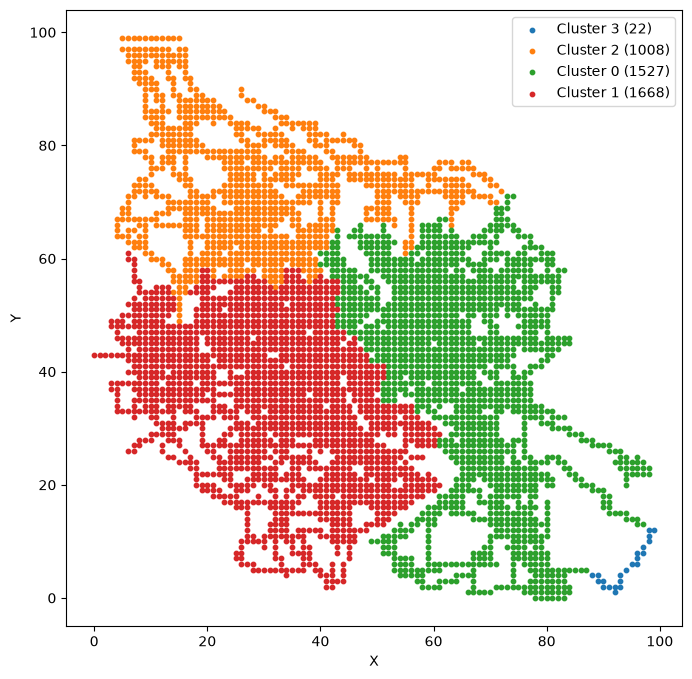

In [ ]:
import random
import time
random.seed(time.time())
communities_res = graph_utils.Graph.detect_leiden_communities(
    objective_function="modularity", graph=spatial_cell_graph, resolution=0.04)

cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)
cell_df = graph_utils.Graph.assign_graph_communities_to_celldf(
    celldf=cell_df, communities=communities_res[0])

print(f"Modularity: {communities_res[1]}")
print(f"N. communities: {communities_res[2]}")

plot_utils.Plot.plot_cell_clusters(
    clusters_dict=cluster_utils.Clustering.clustered_celldf_to_dict(df=cell_df),
    marker_size=10)
plt.show()

In [ ]:
spatial_cell_graph_res = graph_utils.Graph.evaluate_leiden(
    graph=spatial_cell_graph,
    resolutions=np.linspace(start=0.1, stop=0.001, num=300), n_runs=50)

In [ ]:
spatial_cell_graph_res.head()

,resolution,run,objective_function,beta,n_iterations,n_communities,quality
0,0.1,0,modularity,0.01,2,7,0.953725
1,0.1,1,modularity,0.01,2,7,0.952433
2,0.1,2,modularity,0.01,2,7,0.953720
3,0.1,3,modularity,0.01,2,8,0.953944
4,0.1,4,modularity,0.01,2,8,0.953861


In [ ]:
spatial_graph_summary = (
    spatial_cell_graph_res
    .groupby(["resolution"])
    .agg(
        n_communities_mean=("n_communities", "mean"),
        n_communities_std= ("n_communities", "std"),

        quality_mean=("quality", "mean"),
        quality_std=("quality", "std")
    )
    .reset_index()
)

In [ ]:
spatial_graph_summary.head()

,resolution,n_communities_mean,n_communities_std,quality_mean,quality_std
0,0.001000,1.0,0.0,0.999000,0.0
1,0.001331,1.0,0.0,0.998669,0.0
2,0.001662,1.0,0.0,0.998338,0.0
3,0.001993,1.0,0.0,0.998007,0.0
4,0.002324,1.0,0.0,0.997676,0.0


In [ ]:
spatial_graph_summary.sort_values(by=["n_communities_mean", "quality_mean"],
                                ascending=[True, False], inplace=True)

In [ ]:
import pandas as pd
with pd.option_context("display.max_rows", None, "display.max_columns", 1000):
    print(spatial_graph_summary[(2 < spatial_graph_summary["n_communities_mean"])
                        & (4 > spatial_graph_summary["n_communities_mean"])]
[["resolution", "n_communities_mean", "n_communities_std", "quality_mean"]])

     resolution  n_communities_mean  n_communities_std  quality_mean
58     0.020204                2.02           0.141421      0.979895
59     0.020535                2.08           0.274048      0.979582
63     0.021860                2.16           0.370328      0.978432
64     0.022191                2.16           0.370328      0.978192
65     0.022522                2.18           0.388088      0.978053
69     0.023846                2.18           0.388088      0.977290
66     0.022853                2.20           0.404061      0.977883
71     0.024508                2.20           0.404061      0.977030
68     0.023515                2.22           0.418452      0.977418
67     0.023184                2.24           0.431419      0.977642
70     0.024177                2.24           0.431419      0.977110
60     0.020866                2.26           0.443087      0.979266
72     0.024839                2.26           0.443087      0.976812
73     0.025171                2.2

## **4. Mining communities (probability graph)**

In [ ]:
probability_cell_graph = graph_utils.Graph.create_cell_transition_probability_graph(trace=trace)

In [ ]:
print(f"Nodes: {probability_cell_graph.number_of_nodes()}")
print(f"Edges: {probability_cell_graph.number_of_edges()}")

Nodes: 4225
Edges: 15576


Modularity: 0.9925201438432923
N. communities: 3


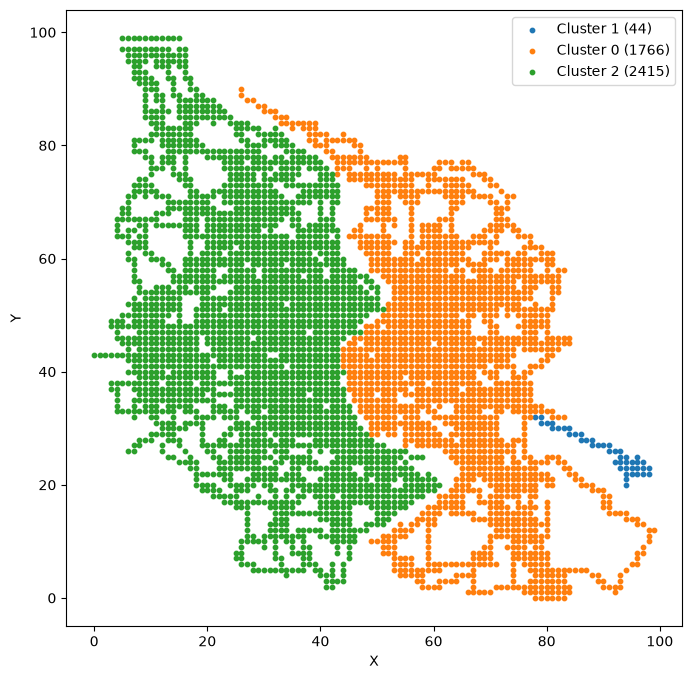

In [ ]:
import random
import time
random.seed(time.time())
communities_res = graph_utils.Graph.detect_leiden_communities(
    objective_function="modularity", graph=probability_cell_graph,
    resolution=0.012)

cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)
cell_df = graph_utils.Graph.assign_graph_communities_to_celldf(
    celldf=cell_df, communities=communities_res[0])

print(f"Modularity: {communities_res[1]}")
print(f"N. communities: {communities_res[2]}")

plot_utils.Plot.plot_cell_clusters(
    clusters_dict=cluster_utils.Clustering.clustered_celldf_to_dict(df=cell_df),
    marker_size=10)
plt.show()

In [ ]:
probability_cell_graph_res = graph_utils.Graph.evaluate_leiden(
    graph=probability_cell_graph,
    resolutions=np.linspace(start=0.1, stop=0.001, num=300), n_runs=50)

In [ ]:
probability_cell_graph_res.head()

,resolution,run,objective_function,beta,n_iterations,n_communities,quality
0,0.1,0,modularity,0.01,2,12,0.973700
1,0.1,1,modularity,0.01,2,11,0.973821
2,0.1,2,modularity,0.01,2,10,0.974488
3,0.1,3,modularity,0.01,2,11,0.974180
4,0.1,4,modularity,0.01,2,11,0.975271


In [ ]:
probability_graph_summary = (
    probability_cell_graph_res
    .groupby(["resolution"])
    .agg(
        n_communities_mean=("n_communities", "mean"),
        n_communities_std= ("n_communities", "std"),

        quality_mean=("quality", "mean"),
        quality_std=("quality", "std")
    )
    .reset_index()
)

In [ ]:
probability_graph_summary.head()

,resolution,n_communities_mean,n_communities_std,quality_mean,quality_std
0,0.001000,1.0,0.0,0.999000,0.0
1,0.001331,1.0,0.0,0.998669,0.0
2,0.001662,1.0,0.0,0.998338,0.0
3,0.001993,1.0,0.0,0.998007,0.0
4,0.002324,1.0,0.0,0.997676,0.0


In [ ]:
probability_graph_summary.sort_values(by=["n_communities_mean", "quality_mean"],
                                ascending=[True, False], inplace=True)

In [ ]:
import pandas as pd
with pd.option_context("display.max_rows", None, "display.max_columns", 1000):
    print(probability_graph_summary[(2 < probability_graph_summary["n_communities_mean"])
                        & (4 > probability_graph_summary["n_communities_mean"])]
[["resolution", "n_communities_mean", "n_communities_std", "quality_mean"]])

    resolution  n_communities_mean  n_communities_std  quality_mean
25    0.009278                2.86           0.350510      0.993774
26    0.009609                2.98           0.141421      0.993606
27    0.009940                2.98           0.141421      0.993423
28    0.010271                2.98           0.141421      0.993264
29    0.010602                2.98           0.141421      0.993113
30    0.010933                3.00           0.000000      0.992948
31    0.011264                3.00           0.000000      0.992786
32    0.011595                3.00           0.000000      0.992614
33    0.011926                3.00           0.000000      0.992455
34    0.012258                3.00           0.000000      0.992285
35    0.012589                3.00           0.000000      0.992123
36    0.012920                3.00           0.000000      0.991962
37    0.013251                3.00           0.000000      0.991810
38    0.013582                3.00           0.0

## **5. Running consensus clustering with basic graph**

#### Results saved (deleted for being large)

Consensus iter 0
Consensus iter 1
Converged: True


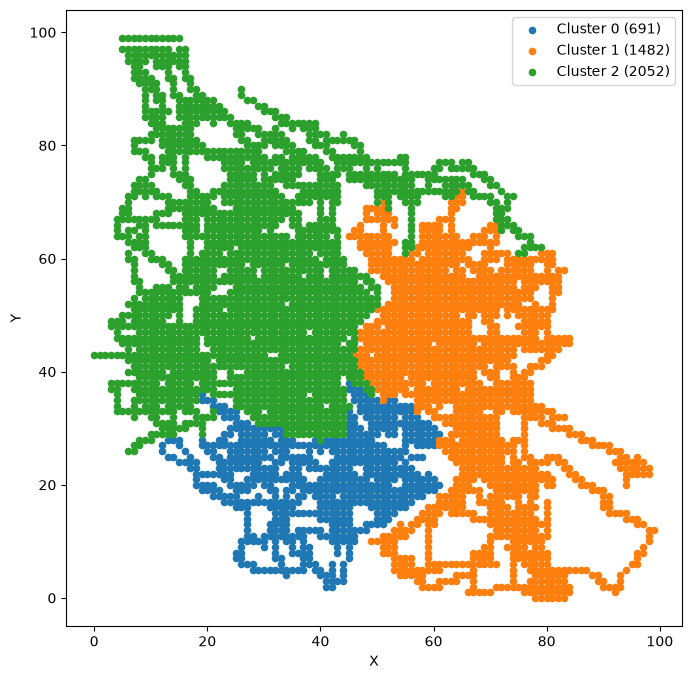

In [ ]:
# res_con = graph_utils.Graph.leiden_consensus(
#     threshold=0.7, graph=basic_cell_graph, resolution=0.045, n_runs=50)

# print(f"Converged: {res_con["converged"]}")

# cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)
# cell_df = graph_utils.Graph.assign_graph_communities_to_celldf(
#     celldf=cell_df, communities=res_con["partition"])

# plot_utils.Plot.plot_cell_clusters(clusters_dict=cluster_utils.Clustering.
#                                    clustered_celldf_to_dict(df=cell_df))
# plt.show()

In [ ]:
# import pickle
# with open(PurePath("..") / "saves" / "c_graph_consensus.pkl", "wb") as f:
#     pickle.dump(res_con, f)

In [5]:
import pickle
with open(PurePath("..") / "saves" / "c_graph_consensus.pkl", "rb") as f:
    res_con = pickle.load(f)

In [6]:
partition = res_con["partition"]

communities = [
    [
        node
        for node, cluster in partition.items()
        if cluster == cluster_id
    ]
    for cluster_id in set(partition.values())
]
import networkx as nx
modularity = nx.community.modularity(
    basic_cell_graph,
    communities,
    weight="weight",
)
print(f"Final partition modularity: {modularity:.3f}")

Final partition modularity: 0.572


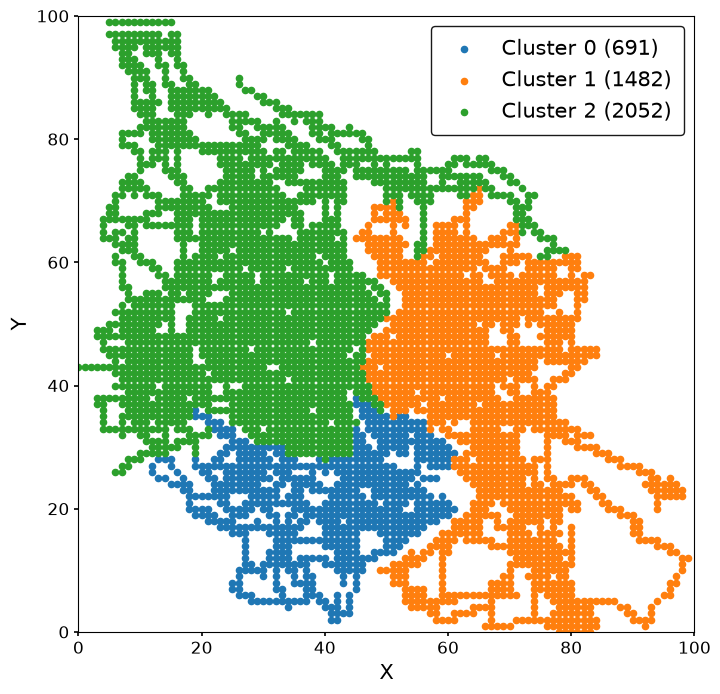

In [11]:
cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)
cell_df = graph_utils.Graph.assign_graph_communities_to_celldf(
    celldf=cell_df, communities=res_con["partition"])

fig, ax = plt.subplots(figsize=(8, 8))

plot_utils.Plot.plot_cell_clusters(clusters_dict=cluster_utils.Clustering.
                                   clustered_celldf_to_dict(df=cell_df), ax=ax)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=12,
    length=3,
    width=1.2
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_yticks([0, 20, 40, 60, 80, 100])

ax.legend(
    loc="upper right",
    fontsize=15,
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="black",
    facecolor="white",
    handlelength=2.0,
    borderpad=0.6)

ax.set_xlabel("X", fontsize=15)
ax.set_ylabel("Y", fontsize=15)

fig.savefig(
    "g_clust.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## **6. Comparing induced vehicles clusters from different communities**

In [9]:
cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)
cell_df.head()

,start_c,end_c,avg_dwell_time,pop
x:y,,,,
0:43,0,0,26.666667,3
10:28,0,0,10.000000,6
10:29,0,0,10.000000,17
10:32,0,0,12.500000,8
10:33,0,0,43.333333,12


In [10]:
cell_df = graph_utils.Graph.assign_graph_communities_to_celldf(celldf=cell_df, communities=res_con["partition"])
cell_df.head()

,start_c,end_c,avg_dwell_time,pop,cluster
x:y,,,,,
0:43,0,0,26.666667,3,2
10:28,0,0,10.000000,6,2
10:29,0,0,10.000000,17,2
10:32,0,0,12.500000,8,2
10:33,0,0,43.333333,12,2


In [11]:
v_clusters = cluster_utils.Clustering.map_vehicles_to_cell_clusters(
    trace=trace, clustered_celldf=cell_df)
v_clusters.head()

,cluster,certainty
vehicle_id,,
0,1,1.0
1,2,1.0
2,2,1.0
3,2,1.0
4,2,1.0


In [12]:
# Moving index to column
v_clusters.reset_index(names="vehicle_id", inplace=True)
v_clusters.head()

,vehicle_id,cluster,certainty
0,0,1,1.0
1,1,2,1.0
2,2,2,1.0
3,3,2,1.0
4,4,2,1.0


In [13]:
v_clusters["cluster"].value_counts() / len(v_clusters)

cluster
2    0.599145
1    0.318303
0    0.082552
Name: count, dtype: float64

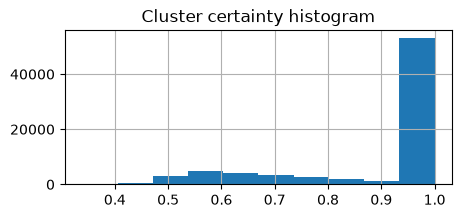

In [ ]:
v_clusters["certainty"].hist(figsize=(5, 2))
plt.title("Cluster certainty histogram")
plt.show()

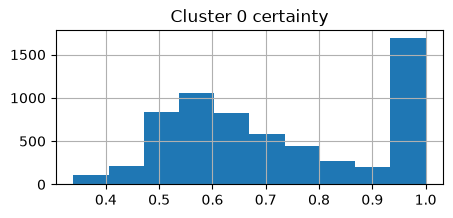

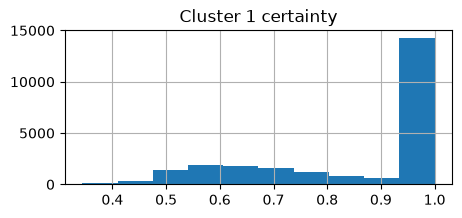

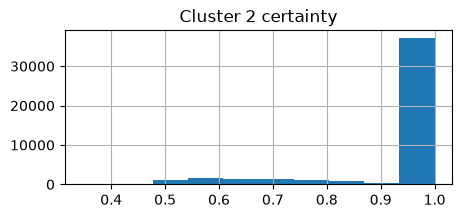

In [ ]:
for cluster_id in (0, 1, 2):
    v_clusters[v_clusters["cluster"] == cluster_id]["certainty"].hist(figsize=(5, 2))
    plt.title(f"Cluster {cluster_id} certainty")
    plt.show()


Cluster 0
[+] Certainty Threshold: 0.5
[+] Num Vehicles: 5849 (7.75 %)

Cluster 1
[+] Certainty Threshold: 0.9
[+] Num Vehicles: 14596 (19.33 %)

Cluster 2
[+] Certainty Threshold: 0.9
[+] Num Vehicles: 37430 (49.57 %)


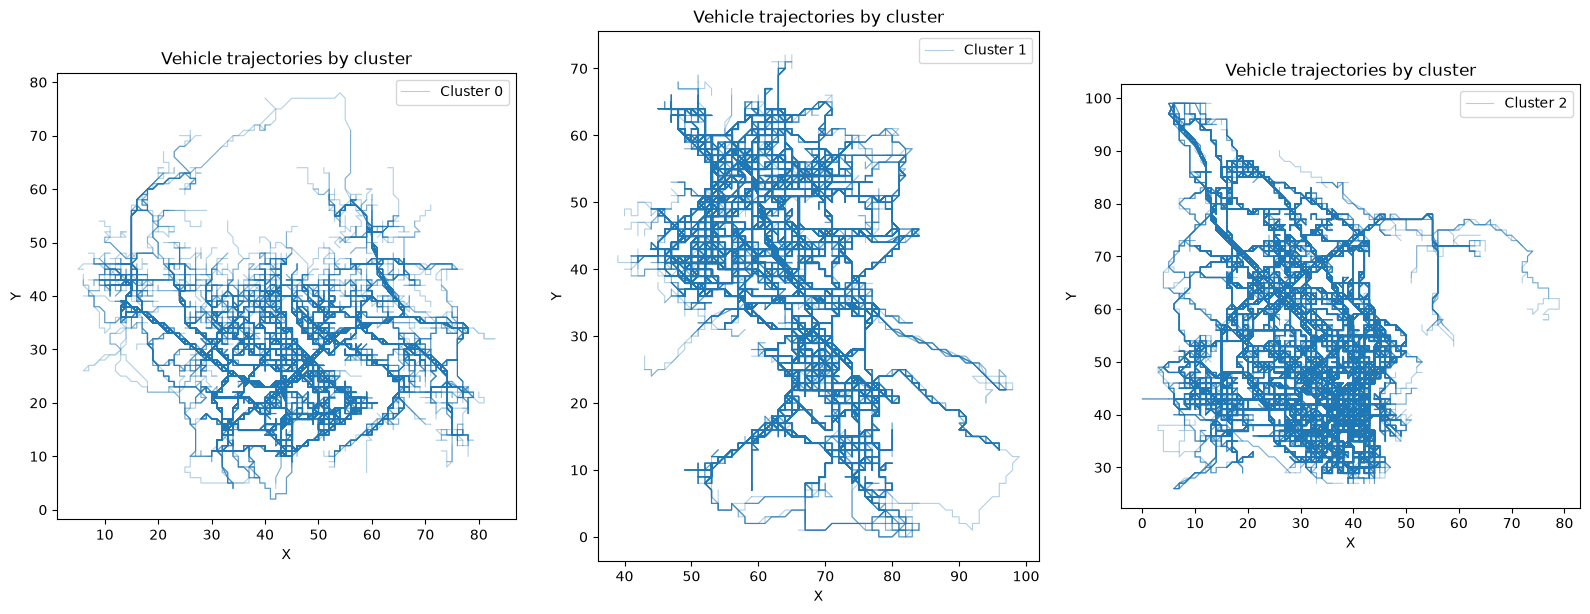

In [14]:
certainty_thresholds = [0.5, 0.9, 0.9]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for cluster_id, certainty_threshold in zip(sorted(v_clusters["cluster"].unique()), certainty_thresholds):

    to_plot = v_clusters[(v_clusters["cluster"] == cluster_id)
                        & (v_clusters["certainty"] >= certainty_threshold)]

    print()
    print(f"Cluster {cluster_id}")
    print(f"[+] Certainty Threshold: {certainty_threshold}")
    print(f"[+] Num Vehicles: {len(to_plot)} ({100 * len(to_plot)/trace["vehicle_id"].nunique():.2f} %)")
    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace, clusters=to_plot, ax=ax[cluster_id])

plt.tight_layout()
plt.savefig("veic_clust_from_g.png")
plt.show()

In [21]:
v_df = feature_utils.Features.create_basic_vehicle_df(trace=trace)

In [22]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,280,16,0.057143,3.166598,3.896292
1,660,35,0.053030,9.093438,4.847520
2,400,27,0.067500,6.107182,4.534184
3,230,14,0.060870,2.945942,3.675311
4,740,41,0.055405,9.749632,5.136696


In [23]:
v_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=v_df, features=v_df.columns.tolist())

In [24]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,0.205044,0.323697,0.378576,0.711783,0.675063
2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,0.449492,0.642298,0.556510,0.867275,0.947794


In [25]:
# Moving index to column
v_df.reset_index(names="vehicle_id", inplace=True)

In [26]:
v_df.head()

,vehicle_id,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
0,0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,1,0.205044,0.323697,0.378576,0.711783,0.675063
2,2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,4,0.449492,0.642298,0.556510,0.867275,0.947794


In [27]:
v_df_clusters = v_df.merge(v_clusters, on="vehicle_id", how="inner")
v_df_clusters.head()

,vehicle_id,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy,cluster,certainty
0,0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071,1,1.0
1,1,0.205044,0.323697,0.378576,0.711783,0.675063,2,1.0
2,2,-0.589413,-0.101105,1.462592,0.004162,0.379546,2,1.0
3,3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485,2,1.0
4,4,0.449492,0.642298,0.556510,0.867275,0.947794,2,1.0


In [29]:
v_df_clusters.describe()

,vehicle_id,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy,cluster,certainty
count,75516.000000,75516.000000,7.551600e+04,7.551600e+04,75516.000000,7.551600e+04,75516.000000,75516.000000
mean,37757.500000,0.000000,-2.408747e-17,1.595795e-16,0.000000,-5.540118e-16,1.516593,0.897391
std,21799.735801,1.000007,1.000007e+00,1.000007e+00,1.000007,1.000007e+00,0.644076,0.171053
min,0.000000,-1.781098,-1.481709e+00,-3.544316e+00,-1.442992,-3.896791e+00,0.000000,0.338983
25%,18878.750000,-0.742193,-7.383067e-01,-6.942732e-01,-0.748304,-6.261150e-01,1.000000,0.794489
50%,37757.500000,-0.131072,-2.604051e-01,-6.047096e-02,-0.280379,7.451855e-02,2.000000,1.000000
75%,56636.250000,0.602273,5.360977e-01,6.577479e-01,0.548252,7.374856e-01,2.000000,1.000000
max,75515.000000,10.471871,6.695719e+00,3.897373e+00,6.341940,2.562611e+00,2.000000,1.000000


In [30]:
for c in (0, 1, 2):
    print("CLUSTER", c)
    print(v_df_clusters[v_df_clusters["cluster"] == c][["trip_duration", "entropy", "radius_of_gyration"]].describe().loc[["25%", "75%"]])

CLUSTER 0
     trip_duration   entropy  radius_of_gyration
25%      -0.467189 -0.011442           -0.371227
75%       0.907833  1.040412            0.882870
CLUSTER 1
     trip_duration   entropy  radius_of_gyration
25%      -0.528301 -0.343376           -0.584899
75%       0.938389  0.988515            1.046830
CLUSTER 2
     trip_duration   entropy  radius_of_gyration
25%      -0.833861 -0.781185           -0.824195
75%       0.327268  0.485278            0.168118


In [ ]:
v_clusters[["vehicle_id", "cluster"]].to_csv("vc_from_g.csv",
                                             index=False, sep=";", header=False)

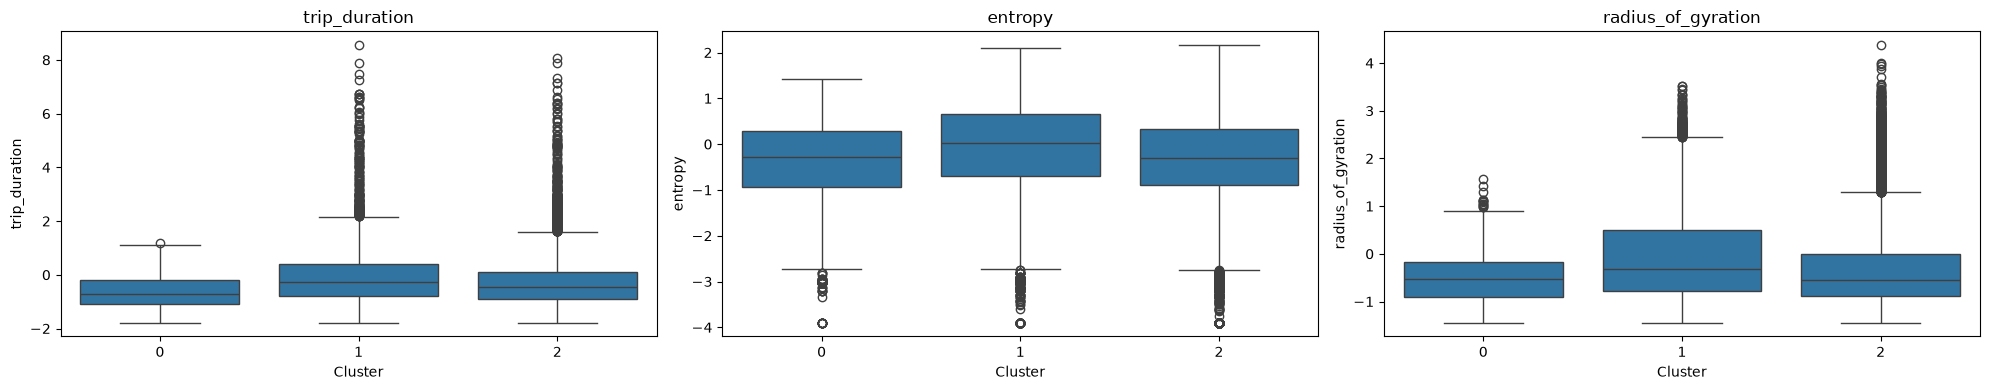

In [23]:
certainty_thresholds = 0.4
plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_df_clusters[v_df_clusters["certainty"] > certainty_threshold],
    features=["trip_duration", "entropy", "radius_of_gyration"])
plt.show()

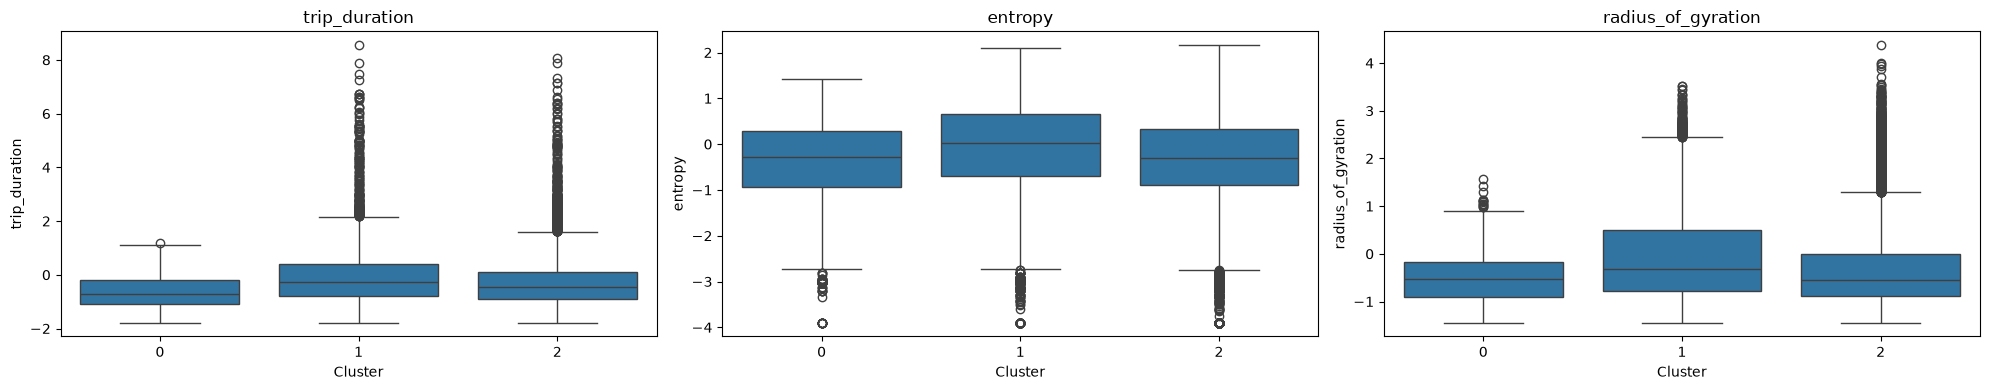

In [24]:
certainty_thresholds = 0.4
plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_df_clusters[v_df_clusters["certainty"] > certainty_threshold],
    features=["trip_duration", "entropy", "radius_of_gyration"])
plt.show()

Cluster 0


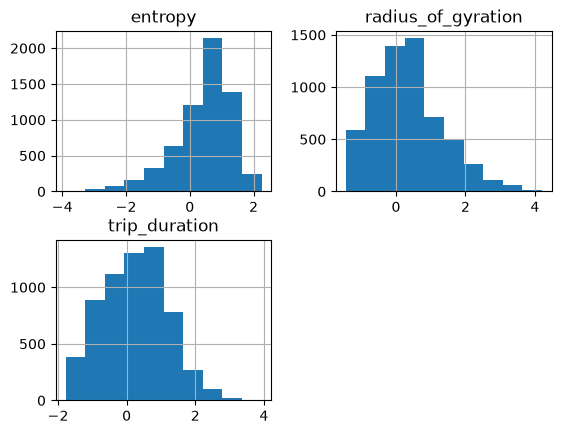

Cluster 1


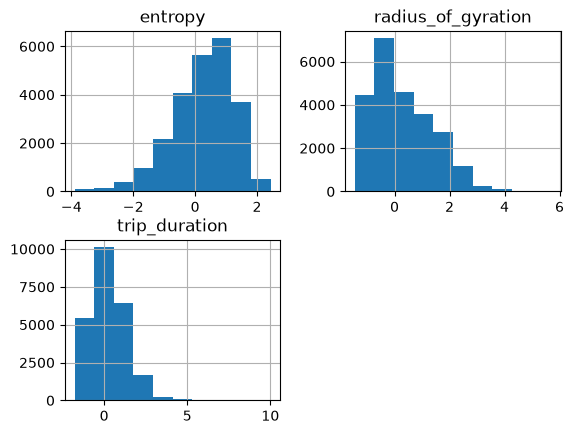

Cluster 2


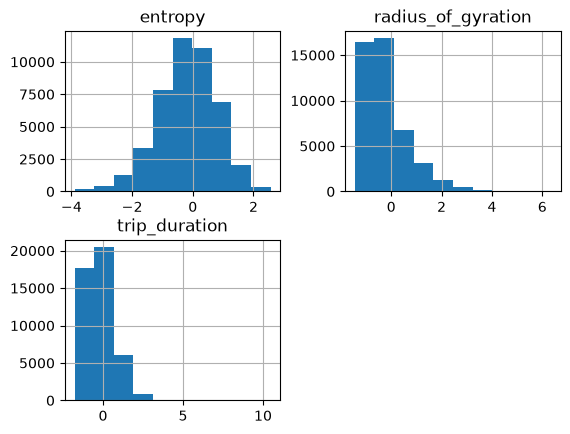

In [25]:
for cluster_id in (0, 1, 2):

    print(f"Cluster {cluster_id}")
    v_df_clusters[v_df_clusters["cluster"] == cluster_id] \
    [["entropy", "radius_of_gyration", "trip_duration"]].hist()
    plt.show()

## **7. Conclusions**

#### 1. Using the graph with spatial weights to mine 3 communities (or any number) does not seem to offer a sensitivity advantage over the basic graph; adjacent weights seem redundant;

#### 2. The probability graph offers big sensitivity advantage when trying to mine 3 communities, but they are very unbalanced

#### 3. The basic graph was chosen to run the consensus community mining; the most frequent communities are each at one side of the river

#### 4. Vehicles' clusters induced from communities have a notably high certainty; however, their feature difference is not so expressive as from direct clusters or cell induced clusters. The reason for that is probably that big urban partitions exhibit samples of multiple mobility patterns